# Ai2020 기반 DFN 모델 Parameterization 및 검증

## 연구 추진 배경 — 충전 프로토콜 최적화 연구

이 노트북은 다음 흐름을 하나의 재현 가능한 분석으로 정리한다.

1. **Chapter 1:** Ai2020 기반 DFN 모델 선정과 기존 모델의 충전 적용 한계 확인
2. **Chapter 2:** 셀 분해 및 전극별 실험을 이용한 단계적 parameterization
3. **최종 선정:** 실험 기반 A값 $k_n=5.54\times10^{-7}$, $b_n=2.914$를 적용한 모델
4. **검증:** 0.5C·1C·2C 충·방전 전압의 실험 branch 시간 10–90% RMSE/MAE 평가

> 중요: 본 노트북에서 “20 mV 이하”는 **전체 원시 시간구간이 아니라 실험 branch 시간 10–90% 구간의 충·방전 통합 RMSE**를 뜻한다.

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_workspace(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "work" / "brugg-all15").exists() and (candidate / "outputs").exists():
            return candidate
    raise FileNotFoundError("work/brugg-all15과 outputs가 있는 workspace를 찾지 못했습니다.")


WORKSPACE = find_workspace(Path.cwd().resolve())
REPO = WORKSPACE / "work" / "brugg-all15"
LEGACY_OUT = REPO / "outputs"
CURRENT_OUT = WORKSPACE / "outputs"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

print("Workspace:", WORKSPACE)
print("Repository:", REPO)

Workspace: C:\Users\user\Documents\Codex\2026-10-22\https-github-com-rinny-hi-ai2020
Repository: C:\Users\user\Documents\Codex\2026-10-22\https-github-com-rinny-hi-ai2020\work\brugg-all15


## 전체 연구 흐름

**원논문 구현 검증 및 파라미터 신뢰성 검토**
$\rightarrow$ **대상 셀 분해와 전극별 측정**
$\rightarrow$ **OCP/window/geometry/$D_s$/kinetics의 단계적 반영**
$\rightarrow$ **제한된 파라미터만 fitting 검토**
$\rightarrow$ **0.5C·1C·2C 충·방전 독립 검증**
$\rightarrow$ **충전 프로토콜 최적화에 사용할 최종 DFN 모델 선정**

최종 목적은 단자전압만 맞추는 것이 아니라, 실험 근거가 있는 파라미터를 우선 적용하면서 충·방전 오차를 함께 줄이고 내부상태 예측의 신뢰성을 확보하는 것이다.

# Chapter 1. 연구 목적 및 Ai2020 모델 선정

## 1.1 DFN 기반 고속충전 프로토콜 최적화 목적

고속충전 프로토콜은 충전시간을 줄이면서도 다음 제약을 만족해야 한다.

- 단자전압 상한
- 음극 전위 하한 및 Li plating 위험
- 전극·전해질 농도 한계
- 온도 및 열화 관련 제약

DFN 모델은 전극 두께 방향의 전해질 수송, 입자 내부 고체확산, 전극반응 및 전위를 동시에 계산한다. 따라서 전류 프로파일을 입력하면 단자전압뿐 아니라 직접 측정하기 어려운 음극 전위와 농도분포를 예측할 수 있다.

## 1.2 DFN 기반 최적화 개념

$$
\min_{I(t)}\;t_{\mathrm{charge}}
$$

subject to

$$
V_{\min}\le V(t)\le V_{\max},\qquad
\phi_{s,n}-\phi_{e,n}\ge 0\;\mathrm{V\;vs.\;Li/Li^+}
$$

단, 내부 전위 예측은 parameterization이 잘못되면 단자전압이 비슷해도 달라질 수 있으므로 실험 기반 파라미터 검토가 선행되어야 한다.

## 1.3 Ai2020 모델 및 대상 셀 선정 근거

- Ai2020은 대상 Enertech 계열 셀에 대한 PyBaMM DFN parameter set을 제공한다.
- 전극·분리막·전해질·OCP 함수가 구성돼 있어 원논문 구현을 재현하고 실험값을 단계적으로 대체하기 용이하다.
- 다만 공개 parameter set을 그대로 적용하면 대상 셀의 실제 전극 OCP, stoichiometry window 및 kinetic/transport 특성과 차이가 남을 수 있다.

## 1.4 기존 Ai2020 적용 모델의 한계

Chapter 1 비교에서는 원시 baseline을 제외하고 다음 두 조건만 비교한다.

- **기존 적용 모델:** Ai2020 양·음극 OCP + 재최적화 stoichiometry window
- **OCP 개선 모델:** 실측 양극 GITT OCP + Ai2020 음극 OCP + 재최적화 window

두 모델은 공통 geometry와 전해질 단위보정을 공유한다. 따라서 차이는 주로 양극 OCP와 이에 연동된 window 변화로 해석한다.

In [2]:
stage1_metrics_path = LEGACY_OUT / "Stage1_De_RpRn_OCP_window_양극OCP_3단계_동적전압_RMSE_MAE.csv"
stage1 = pd.read_csv(stage1_metrics_path, encoding="utf-8-sig")

stage_old = "B · Ai2020 OCP + window 재최적화"
stage_new = "C · 측정 양극 OCP + window 재최적화"
chapter1 = stage1.loc[stage1["stage"].isin([stage_old, stage_new])].copy()

chapter1_summary = (
    chapter1.groupby(["stage", "direction"], as_index=False)
    .agg(
        RMSE_10_70_mV=("center_10_70_RMSE_mV", "mean"),
        MAE_10_70_mV=("center_10_70_MAE_mV", "mean"),
        Full_RMSE_mV=("full_RMSE_mV", "mean"),
        Full_MAE_mV=("full_MAE_mV", "mean"),
    )
)
display(chapter1_summary.round(2))

,stage,direction,RMSE_10_70_mV,MAE_10_70_mV,Full_RMSE_mV,Full_MAE_mV
0,B · Ai2020 OCP + window 재최적화,Charge,57.01,52.32,54.65,47.51
1,B · Ai2020 OCP + window 재최적화,Discharge,34.52,31.40,54.20,45.13
2,C · 측정 양극 OCP + window 재최적화,Charge,46.81,44.32,48.74,40.94
3,C · 측정 양극 OCP + window 재최적화,Discharge,29.13,25.16,44.14,36.40


C:\Users\user\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51116 (\N{HANGUL SYLLABLE JAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\user\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\user\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51201 (\N{HANGUL SYLLABLE JEOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\user\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\user\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 52769 (

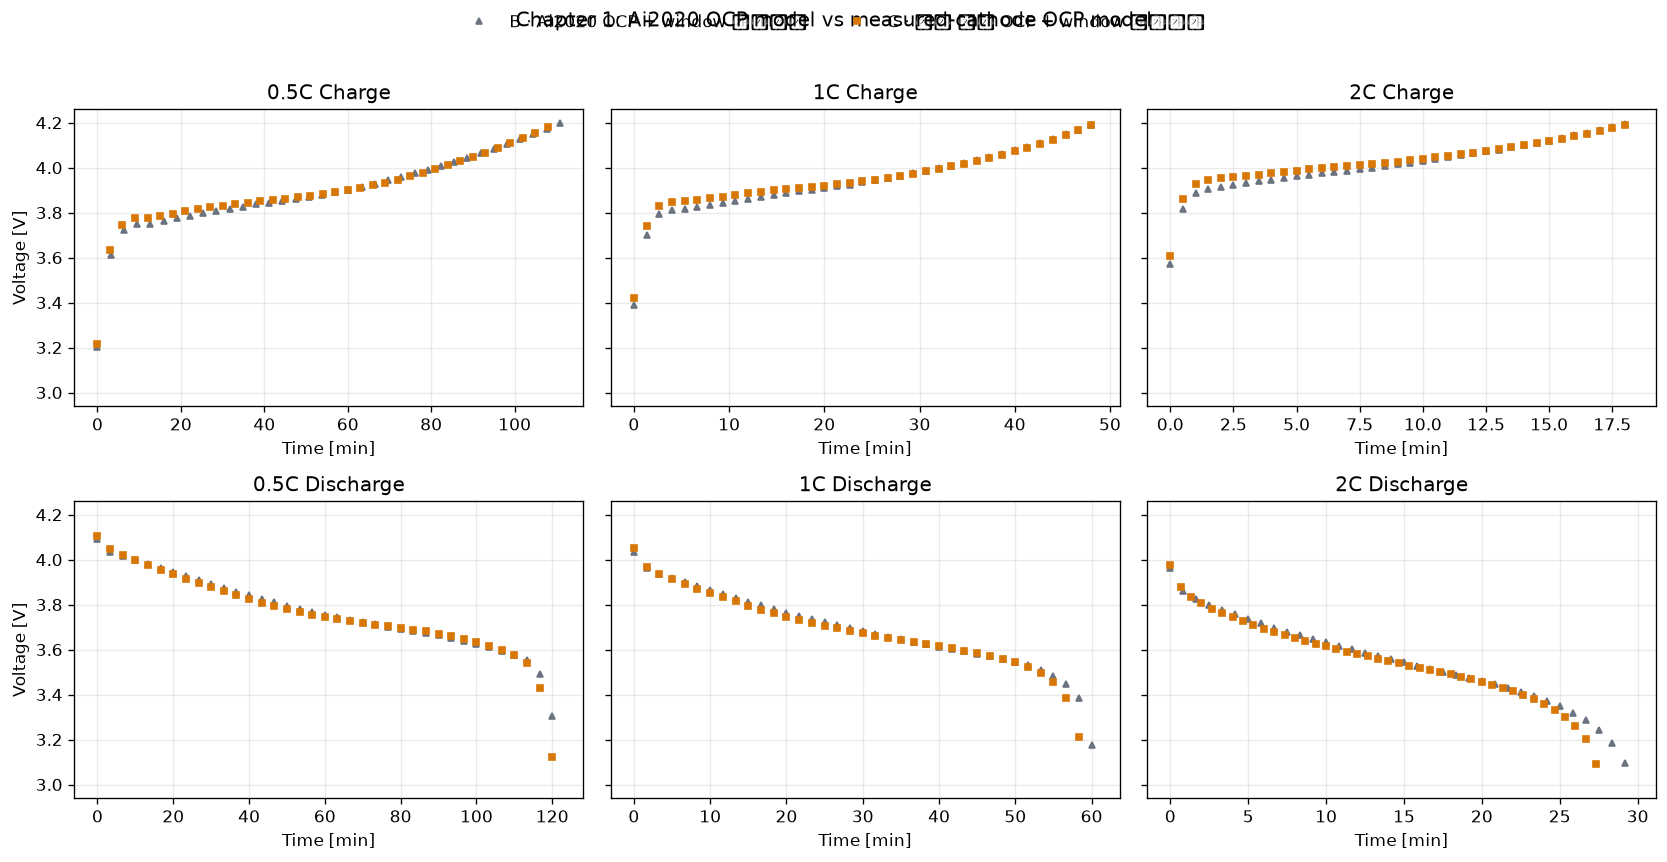

In [3]:
stage1_curves = pd.read_csv(
    LEGACY_OUT / "Stage1_De_RpRn_OCP_window_양극OCP_3단계_동적전압_곡선.csv",
    encoding="utf-8-sig",
)
stage1_curves = stage1_curves.loc[stage1_curves["stage"].isin([stage_old, stage_new])]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
colors = {stage_old: "#6b7280", stage_new: "#d97706"}
markers = {stage_old: "^", stage_new: "s"}

for row, direction in enumerate(["Charge", "Discharge"]):
    for col, rate in enumerate([0.5, 1.0, 2.0]):
        ax = axes[row, col]
        cond = stage1_curves.loc[
            (stage1_curves["C_rate"] == rate)
            & (stage1_curves["direction"].str.lower() == direction.lower())
        ]
        exp = cond.loc[cond["series"].str.lower().str.contains("exp")]
        if exp.empty:
            # 저장 파일에서 실험 series 이름이 다른 경우 첫 비-DFN series 사용
            exp = cond.loc[~cond["series"].str.lower().eq("dfn")]
        if not exp.empty:
            first_stage = exp["stage"].iloc[0]
            exp = exp.loc[exp["stage"].eq(first_stage)]
            ax.plot(exp["time_min"], exp["voltage_V"], color="black", lw=1.6, label="Experiment")

        for model in [stage_old, stage_new]:
            sim = cond.loc[(cond["stage"] == model) & (cond["series"].str.lower() == "dfn")]
            if sim.empty:
                continue
            every = max(1, len(sim) // 35)
            ax.plot(
                sim["time_min"], sim["voltage_V"], linestyle="none",
                marker=markers[model], markevery=every, ms=3.2,
                color=colors[model], label=model,
            )
        ax.set_title(f"{rate:g}C {direction}")
        ax.set_xlabel("Time [min]")
        if col == 0:
            ax.set_ylabel("Voltage [V]")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
fig.suptitle("Chapter 1: Ai2020 OCP model vs measured-cathode OCP model", y=1.02)
fig.tight_layout()
plt.show()

### Chapter 1 결론

기존 Ai2020 적용 모델은 방전보다 충전에서 더 큰 체계적 오차를 보였다. 실측 양극 GITT OCP와 재최적화 window를 적용하면 충전과 방전 오차가 모두 감소한다. 그러나 OCP/window만 변경한 단계에서는 고율 동적전압 오차가 충분히 작지 않으므로, Chapter 2에서 geometry, $D_s$, $k_p$, $k_n$을 실험 기반으로 보정한다.

# Chapter 2. 실험 기반 DFN Parameterization 및 Fitting 전략

## 2.1 보정 과정 요약

1. 원논문/PyBaMM 구현 및 단위 검증
2. 셀 teardown과 전극별 geometry 평가
3. 양·음극 OCP 측정 및 최종 OCP 조합 선정
4. C/50 qOCV 기반 stoichiometry window 재최적화
5. GITT 기반 apparent solid diffusivity 적용
6. EIS–DRT 기반 $R_{ct}\rightarrow k_p,k_n$ 환산
7. 직접 확정하기 어려운 파라미터만 제한적으로 fitting 검토
8. 0.5C·1C·2C 충·방전 전압과 SoC별 음극 전위 검증

최종 모델의 목표는 특정 충전곡선 하나가 아니라 **충·방전 전체 전압 오차를 줄이면서 물리적 근거를 유지하는 것**이다.

In [4]:
# A값을 적용한 현재 최종 parameter set
FINAL = {
    "Nominal cell capacity [A.h]": 2.356528,
    "Temperature [K]": 298.15,
    "Initial electrolyte concentration [mol.m-3]": 1000.0,
    "Negative electrode OCP": "Ai2020 graphite OCP",
    "Positive electrode OCP": "Measured cathode GITT mean OCP",
    "x0": 0.0038033652717561297,
    "x100": 0.9541670383294881,
    "y0": 0.9707163439556511,
    "y100": 0.4316462299737839,
    "Maximum concentration in negative electrode [mol.m-3]": 25184.173471116672,
    "Maximum concentration in positive electrode [mol.m-3]": 49143.144524375515,
    "Negative electrode thickness [m]": 76.5e-6,
    "Positive electrode thickness [m]": 68.0e-6,
    "Negative electrode active material volume fraction": 0.610,
    "Positive electrode active material volume fraction": 0.620,
    "Negative particle radius [m]": 3.692e-6,
    "Positive particle radius [m]": 4.239e-6,
    "Negative particle diffusivity [m2.s-1]": 4.1707741459682473e-14,
    "Positive particle diffusivity [m2.s-1]": 6.888175323807748e-14,
    "kp": 4.37e-7,
    "kn": 5.54e-7,
    "Negative electrode Bruggeman coefficient (electrolyte)": 2.914,
    "Separator Bruggeman coefficient (electrolyte)": 1.500,
    "Positive electrode Bruggeman coefficient (electrolyte)": 1.830,
    "Electrolyte parameter set": "Ai2020; diffusivity function × 1e-4 unit correction",
}

parameter_table = pd.DataFrame(
    [(name, value) for name, value in FINAL.items()],
    columns=["Parameter", "Final A-model value"],
)
display(parameter_table)

,Parameter,Final A-model value
0,Nominal cell capacity [A.h],2.356528
1,Temperature [K],298.15
2,Initial electrolyte concentration [mol.m-3],1000.0
3,Negative electrode OCP,Ai2020 graphite OCP
4,Positive electrode OCP,Measured cathode GITT mean OCP
5,x0,0.003803
6,x100,0.954167
7,y0,0.970716
8,y100,0.431646
9,Maximum concentration in negative electrode [m...,25184.173471


## 2.2 Ai2020 셀 teardown 및 전극별 평가

### (1) SEM 기반 전극 기하학

- 음극 평균 입자반경: $R_n=3.692\;\mu\mathrm{m}$
- 양극 평균 입자반경: $R_p=4.239\;\mu\mathrm{m}$
- 전극 두께: $L_n=76.5\;\mu\mathrm{m}$, $L_p=68.0\;\mu\mathrm{m}$
- 활물질 체적분율: $\varepsilon_{s,n}=0.610$, $\varepsilon_{s,p}=0.620$

### (2) 양·음극 OCP 측정 및 선정

- 양극: GITT 반복 측정의 장시간 완화전압 평균 OCP 채택
- 음극: 측정 저율 OCP도 검토했으나 절대 stoichiometry 기준과 동적 재현성 문제를 고려해 Ai2020 graphite OCP 채택
- 최종 조합: **실측 양극 OCP + Ai2020 음극 OCP**

### (3) 저율 충·방전 기반 stoichiometry window

C/50 충·방전 평균 qOCV의 2–98% 구간을 이용해 $x_0,x_{100},y_0,y_{100}$을 재최적화했다. $c_{s,\max}$는 직접 측정값이 아니라 선택 window, 셀 용량, 전극 면적·두께·활물질 분율의 용량 일관성으로 계산했다.

In [5]:
window_inventory = pd.DataFrame([
    ["x0", FINAL["x0"], "qOCV fitting"],
    ["x100", FINAL["x100"], "qOCV fitting"],
    ["y0", FINAL["y0"], "qOCV fitting"],
    ["y100", FINAL["y100"], "qOCV fitting"],
    ["c_s,max,n", FINAL["Maximum concentration in negative electrode [mol.m-3]"], "capacity/window consistency"],
    ["c_s,max,p", FINAL["Maximum concentration in positive electrode [mol.m-3]"], "capacity/window consistency"],
], columns=["Parameter", "Value", "Basis"])
display(window_inventory)

,Parameter,Value,Basis
0,x0,0.003803,qOCV fitting
1,x100,0.954167,qOCV fitting
2,y0,0.970716,qOCV fitting
3,y100,0.431646,qOCV fitting
4,"c_s,max,n",25184.173471,capacity/window consistency
5,"c_s,max,p",49143.144524,capacity/window consistency


### (4) GITT 기반 고체 확산계수 평가

측정 GITT에서 얻은 apparent diffusivity를 고정값으로 사용한다.

$$
D_{s,n}=4.170774\times10^{-14}\;\mathrm{m^2\,s^{-1}}
$$

$$
D_{s,p}=6.888175\times10^{-14}\;\mathrm{m^2\,s^{-1}}
$$

### (5) EIS–DRT 기반 $k_p$ 평가

- $R_{ct,p}=25.387\;\Omega\,\mathrm{cm^2}$
- 현재 최종 모델 입력: $k_p=4.37\times10^{-7}$

### (6) EIS–DRT 기반 $k_n$ 평가

- 적용 근거 $R_{ct,n}=30.6971\;\Omega\,\mathrm{cm^2}$
- A값: $k_n=5.54\times10^{-7}$
- 음극 EIS 면적은 추후 재확인 대상이지만, voltage-only $k_n$ 단독 fitting 결과 $5.53006\times10^{-7}$과 0.18% 차이로 현재 데이터의 전압 최적점 부근이다.

환산 개념은 다음과 같다.

$$
a_s=\frac{3\varepsilon_s}{R},\qquad
j_0=\frac{RT}{F\,R_{ct,A}\,a_sL},\qquad
k=\frac{j_0}{c_{s,\max}\sqrt{c_e\theta(1-\theta)}}
$$

In [6]:
classification = pd.DataFrame([
    ["Particle radius Rn/Rp", "3.692 / 4.239 µm", "SEM/ImageJ", "Measured/derived; fixed"],
    ["Cathode OCP", "Measured GITT mean", "GITT", "Measured; fixed"],
    ["Anode OCP", "Ai2020 graphite", "Ai2020", "Literature; fixed"],
    ["Stoichiometry window", "x0/x100/y0/y100", "C/50 qOCV", "Fitted; fixed"],
    ["c_s,max,n/p", "25184.17 / 49143.14", "Capacity consistency", "Calculated; fixed"],
    ["D_s,n/p", "4.1708e-14 / 6.8882e-14", "GITT", "Measured-derived; fixed"],
    ["k_p", "4.37e-7", "Cathode EIS-DRT", "Measured-derived; fixed"],
    ["k_n", "5.54e-7", "Anode EIS-DRT", "Measured-derived; final A"],
    ["b_n", "2.914", "Ai2020", "Literature; final A"],
    ["b_s / b_p", "1.500 / 1.830", "Ai2020", "Literature; fixed"],
    ["Electrolyte", "Ai2020 corrected", "Ai2020", "Literature/unit-corrected; fixed"],
], columns=["Parameter", "Final value", "Evidence", "Classification"])
display(classification)

,Parameter,Final value,Evidence,Classification
0,Particle radius Rn/Rp,3.692 / 4.239 µm,SEM/ImageJ,Measured/derived; fixed
1,Cathode OCP,Measured GITT mean,GITT,Measured; fixed
2,Anode OCP,Ai2020 graphite,Ai2020,Literature; fixed
3,Stoichiometry window,x0/x100/y0/y100,C/50 qOCV,Fitted; fixed
4,"c_s,max,n/p",25184.17 / 49143.14,Capacity consistency,Calculated; fixed
5,"D_s,n/p",4.1708e-14 / 6.8882e-14,GITT,Measured-derived; fixed
6,k_p,4.37e-7,Cathode EIS-DRT,Measured-derived; fixed
7,k_n,5.54e-7,Anode EIS-DRT,Measured-derived; final A
8,b_n,2.914,Ai2020,Literature; final A
9,b_s / b_p,1.500 / 1.830,Ai2020,Literature; fixed


## 2.3 제한적 fitting 전략

실험값으로 고정 가능한 geometry, OCP, window, $D_s$, $k_p$는 다시 자유롭게 fitting하지 않는다. $k_n$과 $b_n$만 민감도 후보로 검토했으며, 목적함수에는 capacity error를 넣지 않고 충전 전압 잔차만 사용했다.

$$
J(\theta)=\sum_{r\in\{0.5C,1C,2C\}}\sum_{t_i\in T_{10-90\%}}
\left[V_{\mathrm{sim},r}(t_i;\theta)-V_{\mathrm{exp},r}(t_i)\right]^2
$$

- $k_n$ 단독 fitting은 A값과 사실상 동일했다.
- $k_n+b_n$ 동시 fitting은 2C 충전시간과 음극 전위를 개선했지만 방전 전압이 악화되고 상호보상 가능성이 확인됐다.
- 따라서 본 노트북의 최종값은 **A: $k_n=5.54\times10^{-7}$, $b_n=2.914$**이다.

In [7]:
fit_params = pd.read_csv(CURRENT_OUT / "kn_vs_kn_brugg_voltage_only" / "fit_parameters.csv")
fit_summary = pd.read_csv(CURRENT_OUT / "kn_vs_kn_brugg_voltage_only" / "summary_metrics.csv")

display(fit_params[["Model", "kn", "brugg_n", "Objective_voltage_RMSE_mV"]].round(6))
display(
    fit_summary.loc[
        fit_summary["Group"].isin(["Charge", "Discharge", "All"]),
        ["Model", "Group", "Time10_90_RMSE_mV", "Time10_90_MAE_mV"]
    ].round(2)
)

,Model,kn,brugg_n,Objective_voltage_RMSE_mV
0,Initial,0.000001,2.91400,19.897292
1,kn only,0.000001,2.91400,19.897228
2,kn + brugg_n,0.000000,2.43993,18.911607


,Model,Group,Time10_90_RMSE_mV,Time10_90_MAE_mV
0,Initial,Charge,19.73,15.36
1,Initial,Discharge,16.95,13.16
2,Initial,All,18.39,14.26
3,kn only,Charge,19.73,15.35
4,kn only,Discharge,16.96,13.18
5,kn only,All,18.40,14.26
6,kn + brugg_n,Charge,18.68,15.75
7,kn + brugg_n,Discharge,24.77,19.55
8,kn + brugg_n,All,21.94,17.65


## 2.4 A값 최종 모델 구성 코드

아래 셀은 최근 검증 스크립트와 동일한 A값으로 PyBaMM ParameterValues를 구성한다. 전체 DFN 재계산은 시간이 걸리므로 `RUN_FULL_SIMULATION=True`로 바꿀 때만 실행한다.

In [8]:
RUN_FULL_SIMULATION = False

if RUN_FULL_SIMULATION:
    sys.path.insert(0, str(WORKSPACE / "work"))
    from fit_final_kn_vs_kn_brugg import build_stage, solve_continuous

    final_stage = build_stage(kn=5.54e-7, bn=2.914)
    final_runs = solve_continuous(kn=5.54e-7, bn=2.914)
    print("A-model DFN simulation completed:", sorted(final_runs))
else:
    print("Saved validated A-model results are used. Set RUN_FULL_SIMULATION=True to rerun DFN.")

Saved validated A-model results are used. Set RUN_FULL_SIMULATION=True to rerun DFN.


## 2.5 최종 전압 정합도 검증

평가 기준은 실험 branch의 시작·종료시간을 각각 0%와 100%로 두고 그중 **시간 10–90%**를 동일 격자로 보간한 전압 RMSE/MAE이다. Capacity error는 fitting 목적함수에서 제외했다.

In [9]:
summary = pd.read_csv(CURRENT_OUT / "kn_vs_kn_brugg_voltage_only" / "summary_metrics.csv")
amodel = summary.loc[summary["Model"].eq("Initial")].copy()

voltage_result = amodel[[
    "Group", "Time10_90_RMSE_mV", "Time10_90_MAE_mV",
    "Full_RMSE_mV", "Full_MAE_mV",
]].rename(columns={"Group": "Direction"})
display(voltage_result.round(2))

center_all = float(amodel.loc[amodel["Group"].eq("All"), "Time10_90_RMSE_mV"].iloc[0])
center_charge = float(amodel.loc[amodel["Group"].eq("Charge"), "Time10_90_RMSE_mV"].iloc[0])
center_discharge = float(amodel.loc[amodel["Group"].eq("Discharge"), "Time10_90_RMSE_mV"].iloc[0])

print(f"Charge 10–90% RMSE    : {center_charge:.2f} mV")
print(f"Discharge 10–90% RMSE : {center_discharge:.2f} mV")
print(f"All 10–90% RMSE       : {center_all:.2f} mV")
assert center_charge < 20 and center_discharge < 20 and center_all < 20
print("PASS: charge, discharge and combined 10–90% RMSE are below 20 mV.")

,Direction,Time10_90_RMSE_mV,Time10_90_MAE_mV,Full_RMSE_mV,Full_MAE_mV
0,Charge,19.73,15.36,48.85,26.16
1,Discharge,16.95,13.16,31.28,21.78
2,All,18.39,14.26,41.02,23.97


Charge 10–90% RMSE    : 19.73 mV
Discharge 10–90% RMSE : 16.95 mV
All 10–90% RMSE       : 18.39 mV
PASS: charge, discharge and combined 10–90% RMSE are below 20 mV.


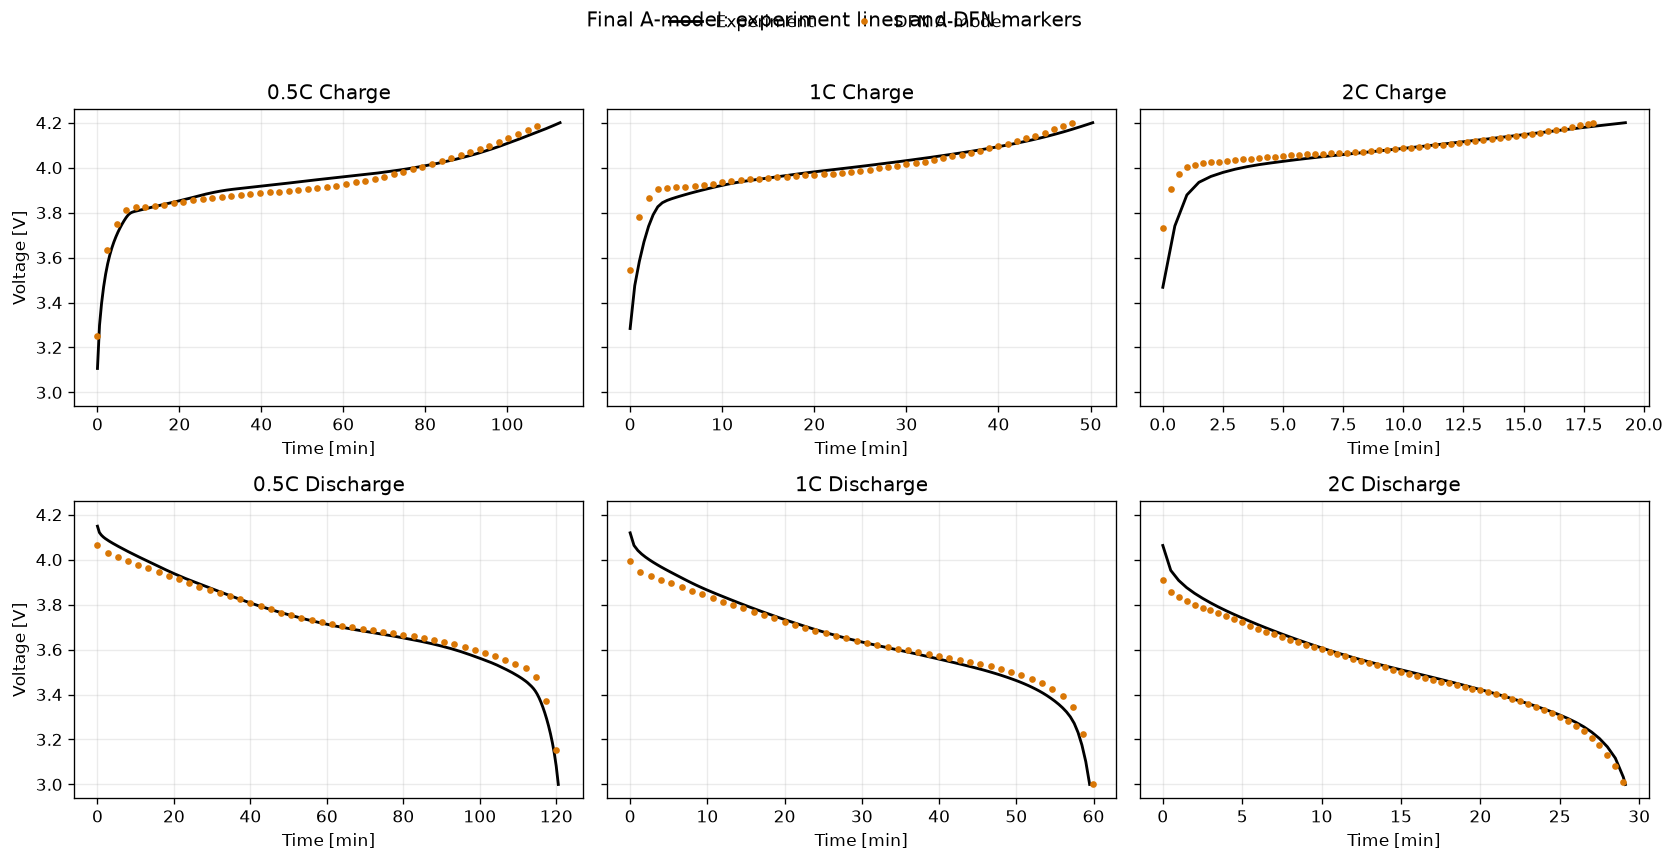

In [10]:
curves = pd.read_csv(CURRENT_OUT / "kn_vs_kn_brugg_voltage_only" / "curves.csv")
curves = curves.loc[curves["Model"].eq("Initial")]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for row, direction in enumerate(["Charge", "Discharge"]):
    for col, rate in enumerate([0.5, 1.0, 2.0]):
        ax = axes[row, col]
        cond = curves.loc[(curves["C_rate"] == rate) & (curves["Direction"] == direction)]
        exp = cond.loc[cond["Series"].eq("Experiment")]
        sim = cond.loc[cond["Series"].eq("Model")]
        ax.plot(exp["Time_min"], exp["Voltage_V"], color="black", lw=1.7, label="Experiment")
        every = max(1, len(sim) // 45)
        ax.plot(
            sim["Time_min"], sim["Voltage_V"], linestyle="none",
            marker="o", markevery=every, ms=3.0, color="#d97706", label="DFN A-model",
        )
        ax.set_title(f"{rate:g}C {direction}")
        ax.set_xlabel("Time [min]")
        if col == 0:
            ax.set_ylabel("Voltage [V]")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.suptitle("Final A-model: experiment lines and DFN markers", y=1.02)
fig.tight_layout()
plt.show()

## 2.6 SoC별 음극 전위 — 충전 프로토콜 적용 전 사후 검증

단일 최소값 대신 공통 절대 SoC 10–59% 구간에서 음극 전위를 확인한다. 0.5C와 1C는 양수이나, 현재 A모델의 2C 음극 전위는 약 SoC 17.6%에서 0 V 이하로 내려간다. 이는 기준전극 실측 검증값이 아니라 DFN 내부 예측이므로, 고속충전 최적화에서는 보수적 제약과 모델 불확실성 검토에 사용한다.

,C_rate,SoC_pct,A_model_anode_mV
0,0.5,10,146.92
1,0.5,20,112.05
2,0.5,30,88.44
3,0.5,40,79.78
4,0.5,50,72.45
5,0.5,59,61.33
6,1.0,10,94.54
7,1.0,20,61.74
8,1.0,30,42.55
9,1.0,40,32.10


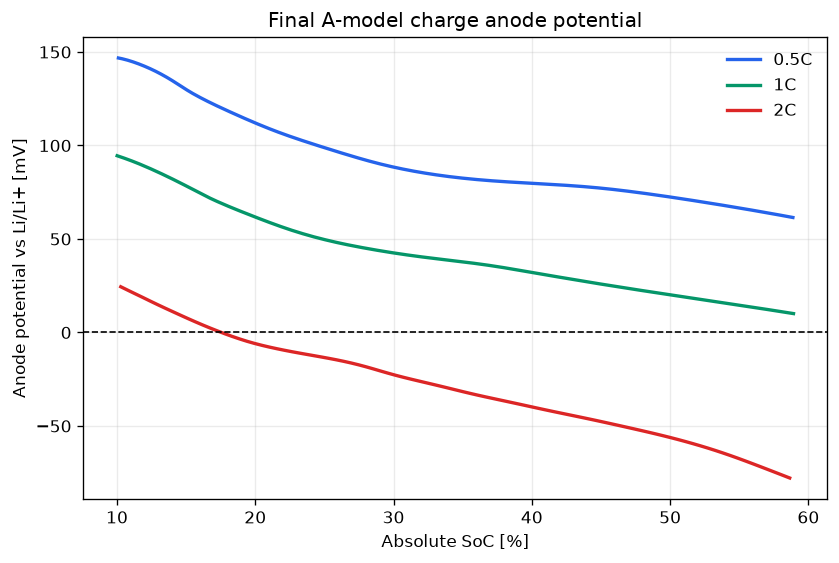

In [11]:
anode = pd.read_csv(CURRENT_OUT / "kn_vs_kn_brugg_voltage_only" / "anode_potential_by_soc.csv")
display(anode[["C_rate", "SoC_pct", "Initial_mV"]].rename(columns={"Initial_mV": "A_model_anode_mV"}))

fig, ax = plt.subplots(figsize=(8, 5))
model_charge = curves.loc[(curves["Direction"] == "Charge") & (curves["Series"] == "Model")]
for rate, color in [(0.5, "#2563eb"), (1.0, "#059669"), (2.0, "#dc2626")]:
    sub = model_charge.loc[model_charge["C_rate"] == rate].sort_values("SOC_pct")
    sub = sub.loc[sub["SOC_pct"].between(10, 59)]
    ax.plot(sub["SOC_pct"], sub["Anode_mV"], lw=2, color=color, label=f"{rate:g}C")
ax.axhline(0, color="black", ls="--", lw=1)
ax.set(xlabel="Absolute SoC [%]", ylabel="Anode potential vs Li/Li+ [mV]",
       title="Final A-model charge anode potential")
ax.legend(frameon=False)
plt.show()

# 최종 선정 모델 및 결론

## 최종 A모델

- **OCP:** Ai2020 음극 + 실측 양극 GITT
- **Window:** C/50 qOCV 재최적화
- **Geometry:** teardown/SEM 기반
- **Diffusion:** GITT 기반 $D_{s,n}$, $D_{s,p}$
- **Kinetics:** EIS–DRT 기반 $k_p$, $k_n=5.54\times10^{-7}$
- **Electrolyte:** 단위 보정 Ai2020, ORegan2022 미적용
- **Bruggeman:** $b_n/b_s/b_p=2.914/1.500/1.830$

## 주요 성과

실험 기반 parameterization 후 0.5C·1C·2C 충·방전의 실험 branch 시간 10–90% 기준으로 다음 결과를 얻었다.

- 충전 RMSE: **19.73 mV**
- 방전 RMSE: **16.95 mV**
- 충·방전 통합 RMSE: **18.39 mV**
- 충·방전 통합 MAE: **14.26 mV**

따라서 사전에 정의한 중앙구간 기준에서 **전압 정합도 20 mV 이하**를 달성했다. 전체 원시 시간구간 RMSE는 cutoff·초기/말단 과도구간 때문에 더 크므로 별도로 표시하며, 20 mV 이하 주장과 혼용하지 않는다.

## 남은 결정

후속 충전 프로토콜 최적화에서는 본 실험 기반 A값을 초기 DFN 모델로 사용한다. 음극 EIS 유효면적을 다시 산정하는 경우에는 별도 버전으로 기록하고 본 기준과 교차 검증한다.